# 02 · From-scratch DPO: HH-RLHF and UltraFeedback (Task 4)
**Settings:** GPU T4 x2 · Internet On · Save & Run All (Commit).

**Needs:** notebook **01**'s output attached (*Add Input → Your Work → Notebooks → 01*).
**Produces:** `outputs/dpo_hh/` and `outputs/dpo_uf/` (≈2–2.5 h each, ≈5 h total; under Kaggle's 12 h limit).

Policy (fp32, trainable) on `cuda:0`, frozen fp16 reference on `cuda:1`. To split across two sessions,
set `RUNS = ["hh"]` for one version and `RUNS = ["uf"]` for the next.

In [1]:
# Code repo (public, or add a GitHub token as a Kaggle secret if private)
REPO_URL = "https://github.com/NifraWahaj/cs5323_PA2.git"
BRANCH = "main"

import os, subprocess, sys
REPO = "/kaggle/working/sprout"
if not os.path.exists(REPO):
    subprocess.run(["git", "clone", "-q", "-b", BRANCH, REPO_URL, REPO], check=True)
else:
    subprocess.run(["git", "-C", REPO, "pull", "-q"], check=True)
os.chdir(REPO)
sys.path.insert(0, REPO)
print(subprocess.run(["git", "log", "--oneline", "-1"], capture_output=True, text=True).stdout)

14109c4 Fix SFT validation OOM on T4; fail notebooks loudly when training fails



In [2]:
# Kaggle's PyTorch already matches the GPU runtime: do NOT reinstall torch.
!python -m pip uninstall -y -q torchao || true
!python -m pip install -q "transformers>=4.43.0,<5" "datasets>=2.18,<5" huggingface_hub accelerate tqdm pyyaml sentencepiece safetensors pytest
!python -m pip install -q -e . --no-deps

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 44.0/44.0 kB 1.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 12.0/12.0 MB 96.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 566.4/566.4 kB 23.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3.3/3.3 MB 88.9 MB/s eta 0:00:00
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
gradio 6.26.0 requires huggingface-hub<2.0,>=1.16.0, but you have huggingface-hub 0.36.2 which is incompatible.
diffusers 0.40.0 requires huggingface-hub<2.0,>=1.23.0, but you have huggingface-hub 0.36.2 which is incompatible.
  Installing build dependencies ... done
  Checking if build backend supports build_editable ... done
  Getting requirements to build editable ... done
  Preparing editable metadata (pyproject.toml) ... done
  Building editable for sproutlm (pyproject.toml) ... done


In [3]:
!nvidia-smi --query-gpu=index,name,memory.total --format=csv
import torch, transformers, datasets
print("torch", torch.__version__, "| transformers", transformers.__version__, "| datasets", datasets.__version__)
print("GPUs visible:", torch.cuda.device_count())
assert torch.cuda.device_count() == 2, "Set Accelerator to GPU T4 x2"

index, name, memory.total [MiB]
0, Tesla T4, 15360 MiB
1, Tesla T4, 15360 MiB
torch 2.11.0+cu128 | transformers 4.57.6 | datasets 4.8.5
GPUs visible: 2


In [4]:
from sproutlm.kaggle_paths import find_run
SFT_BEST = find_run("sft", "best")
print("reference + initial policy:", SFT_BEST)
!cat {SFT_BEST}/sprout_note.json
RUNS = ["hh", "uf"]
import os

reference + initial policy: /kaggle/input/notebooks/nifraw/01notebookgenai/outputs/sft/best
{
  "step": 839,
  "val_loss": 1.3755343536190867,
  "base": "Qwen/Qwen2.5-0.5B"
}

In [5]:
if "hh" in RUNS:
    !PYTORCH_CUDA_ALLOC_CONF=expandable_segments:True TOKENIZERS_PARALLELISM=false python -m sproutlm.dpo_loop --config configs/dpo_hh.yaml \
        sft_checkpoint={SFT_BEST} output_dir=/kaggle/working/outputs/dpo_hh
    assert os.path.exists("/kaggle/working/outputs/dpo_hh/best/sprout_note.json"), "DPO-HH FAILED - see log above"

README.md: 5.77kB [00:00, 23.1MB/s]
harmless-base/train.jsonl.gz: 100%|████████| 13.2M/13.2M [00:00<00:00, 31.8MB/s]
helpful-base/train.jsonl.gz: 100%|█████████| 16.2M/16.2M [00:00<00:00, 49.6MB/s]
helpful-online/train.jsonl.gz: 100%|███████| 20.1M/20.1M [00:00<00:00, 48.4MB/s]
helpful-rejection-sampled/train.jsonl.gz: 100%|█| 25.7M/25.7M [00:00<00:00, 63.7
harmless-base/test.jsonl.gz: 100%|███████████| 743k/743k [00:00<00:00, 4.17MB/s]
helpful-base/test.jsonl.gz: 100%|████████████| 875k/875k [00:00<00:00, 4.61MB/s]
helpful-online/test.jsonl.gz: 100%|████████| 1.05M/1.05M [00:00<00:00, 5.28MB/s]
helpful-rejection-sampled/test.jsonl.gz: 100%|█| 1.36M/1.36M [00:00<00:00, 5.36M
Generating test split: 100%|██████| 8552/8552 [00:00<00:00, 68930.86 examples/s]
The tokenizer you are loading from '/kaggle/input/notebooks/nifraw/01notebookgenai/outputs/sft/best' with an incorrect regex pattern: https://huggingface.co/mistralai/Mistral-Small-3.1-24B-Instruct-2503/discussions/84#69121093e8b480e70

In [6]:
if "uf" in RUNS:
    !PYTORCH_CUDA_ALLOC_CONF=expandable_segments:True TOKENIZERS_PARALLELISM=false python -m sproutlm.dpo_loop --config configs/dpo_uf.yaml \
        sft_checkpoint={SFT_BEST} output_dir=/kaggle/working/outputs/dpo_uf
    assert os.path.exists("/kaggle/working/outputs/dpo_uf/best/sprout_note.json"), "DPO-UF FAILED - see log above"

README.md: 6.53kB [00:00, 25.6MB/s]
data/train_prefs-00000-of-00001.parquet: 100%|█| 226M/226M [00:01<00:00, 136MB/s
data/test_prefs-00000-of-00001.parquet: 100%|█| 7.29M/7.29M [00:00<00:00, 24.5MB
data/test_sft-00000-of-00001.parquet: 100%|█| 3.72M/3.72M [00:00<00:00, 19.4MB/s
data/train_gen-00000-of-00001.parquet: 100%|██| 184M/184M [00:01<00:00, 123MB/s]
data/test_gen-00000-of-00001.parquet: 100%|█| 3.02M/3.02M [00:00<00:00, 11.1MB/s
Generating train_prefs split: 100%|█| 61135/61135 [00:00<00:00, 73956.02 example
Generating train_sft split: 100%|█| 61135/61135 [00:00<00:00, 64919.28 examples/
Generating test_prefs split: 100%|█| 2000/2000 [00:00<00:00, 72257.03 examples/s
Generating test_sft split: 100%|██| 1000/1000 [00:00<00:00, 63777.15 examples/s]
Generating train_gen split: 100%|█| 61135/61135 [00:00<00:00, 98166.28 examples/
Generating test_gen split: 100%|██| 1000/1000 [00:00<00:00, 73174.76 examples/s]
The tokenizer you are loading from '/kaggle/input/notebooks/nifraw/01note

[sprout-plots] /kaggle/working/outputs/plots/dpo_hh.png
[sprout-plots] /kaggle/working/outputs/plots/dpo_uf.png


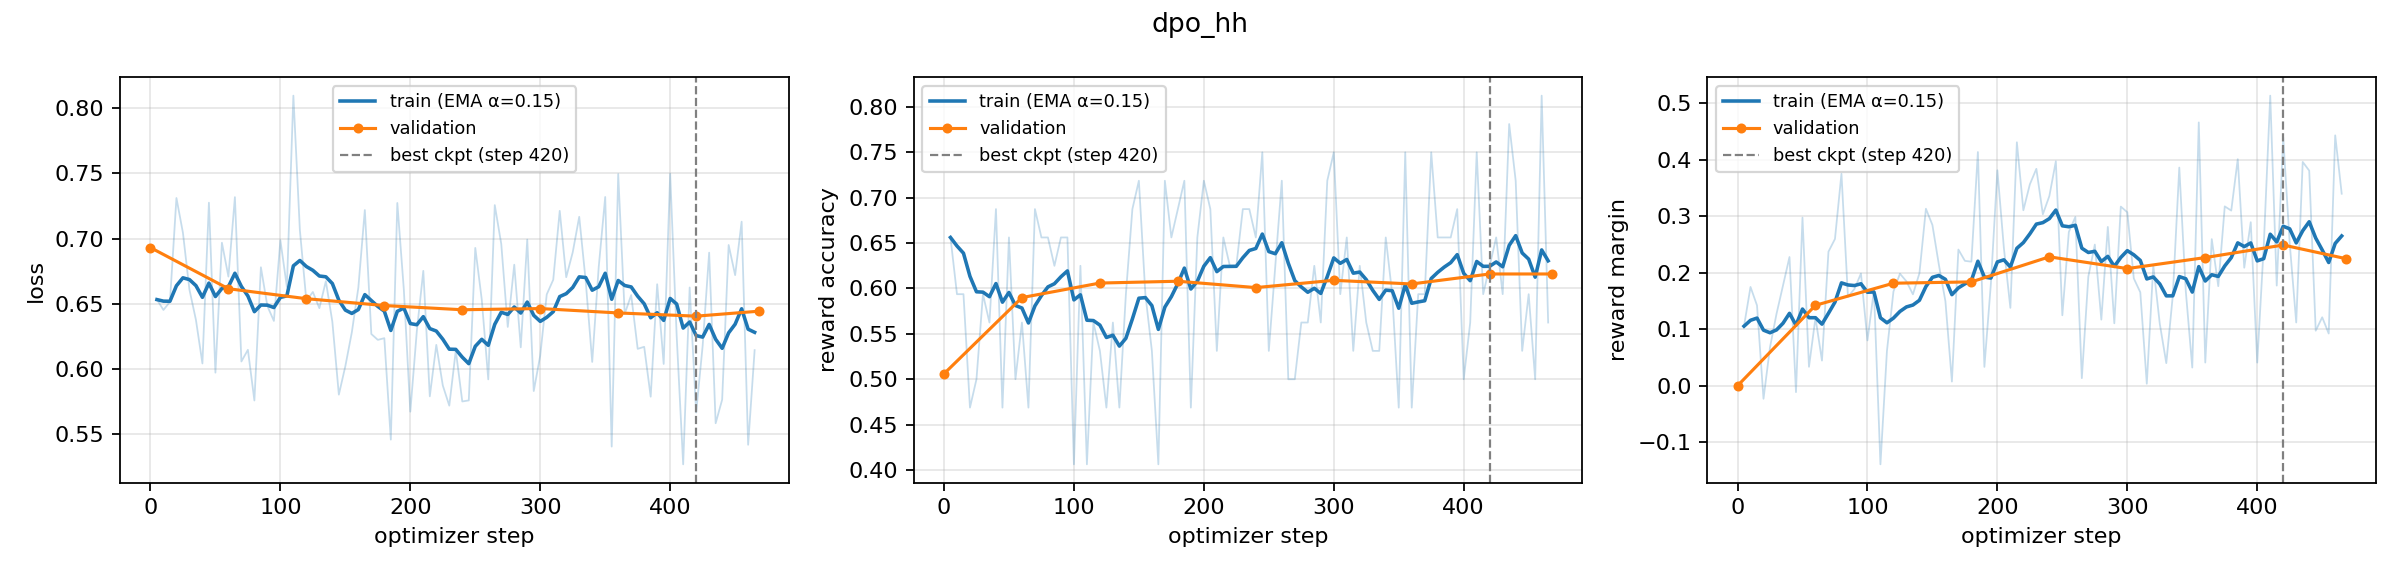

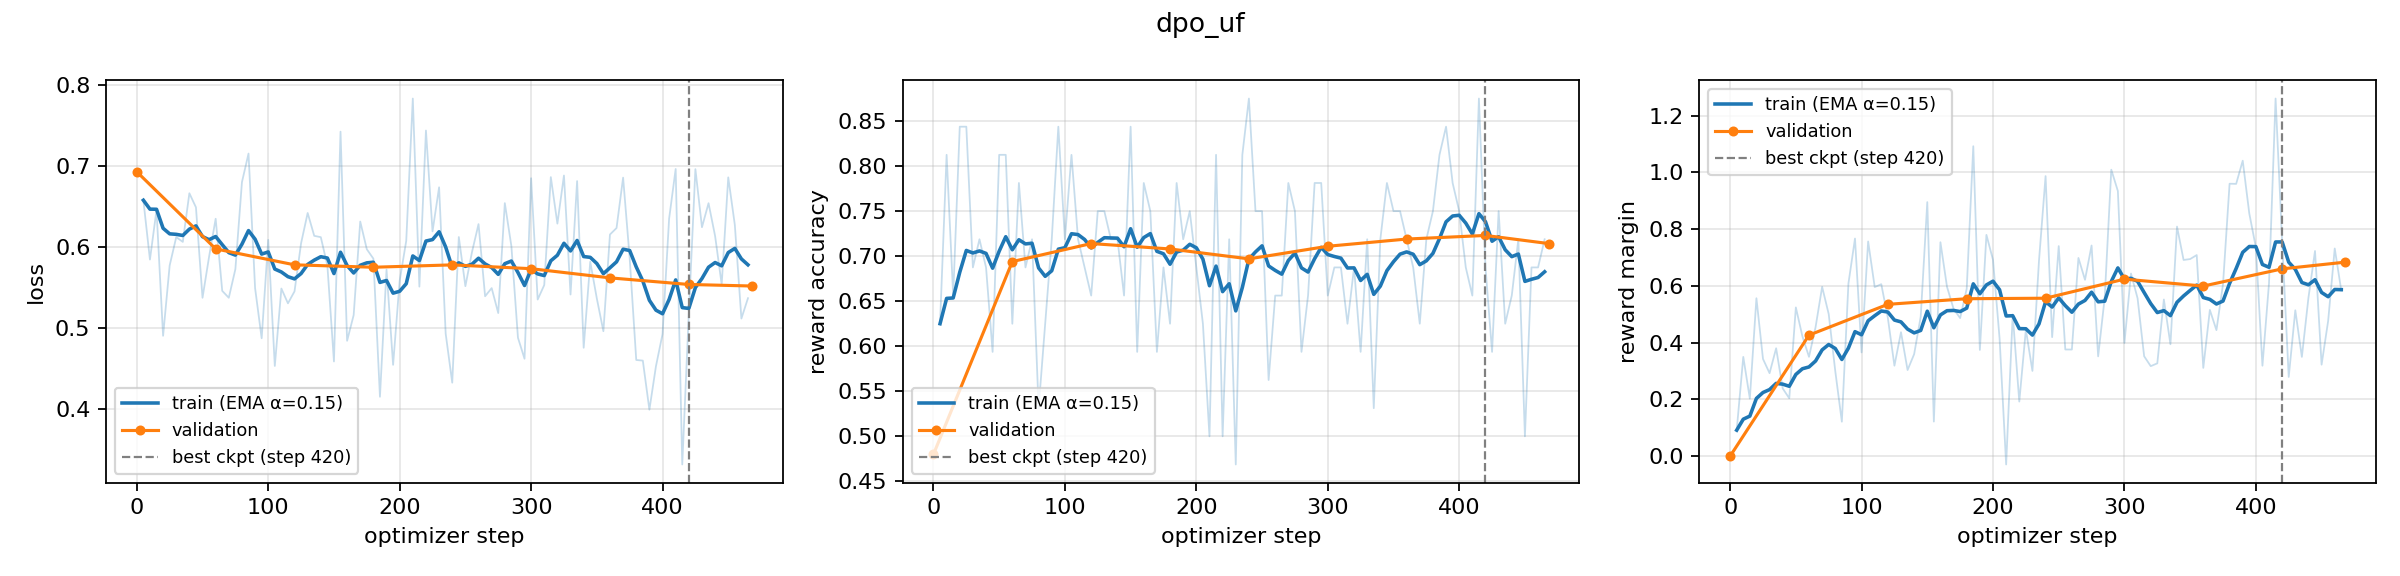

In [7]:
!pip install -q matplotlib
import os
runs = " ".join(f"--run /kaggle/working/outputs/dpo_{r}" for r in RUNS)
!python -m sproutlm.plots {runs} --out /kaggle/working/outputs/plots
from IPython.display import Image, display
for r in RUNS:
    display(Image(f"/kaggle/working/outputs/plots/dpo_{r}.png"))

In [8]:
!for r in dpo_hh dpo_uf; do echo $r; cat /kaggle/working/outputs/$r/best/sprout_note.json 2>/dev/null; echo; done

uf

uf



In [9]:
# Archive this stage (easier to download/attach), then: Save Version -> "Save & Run All (Commit)".
!cd /kaggle/working && zip -qr dpo_run_outputs.zip outputs/dpo_*/metrics.jsonl outputs/dpo_*/config_used.yaml outputs/plots && ls -lh /kaggle/working && du -sh /kaggle/working/outputs/*

total 1.2M
-rw-r--r--  1 root root 473K Oct 15 12:39 dpo_run_outputs.zip
-rw-r--r--  1 root root 730K Oct 15 12:39 __notebook__.ipynb
drwxr-xr-x  5 root root 4.0K Oct 15 12:39 outputs
drwxr-xr-x 13 root root 4.0K Oct 15 09:32 sprout
2.4G	/kaggle/working/outputs/dpo_hh
2.5G	/kaggle/working/outputs/dpo_uf
488K	/kaggle/working/outputs/plots
